# A simple example: a curved 2D posterior

Two parameters with a standard-normal prior, observed through a nonlinear forward model.
The posterior is a curved "banana", far from Gaussian. In two dimensions we can compute it
exactly on a grid and compare.

In [1]:
from dataclasses import replace

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import mgsl

jax.config.update("jax_enable_x64", True)

## The model

The latent `x = (x1, x2)` has prior N(0, I). We observe `x1` (noise standard deviation 1,
so it is barely constrained) and `x2 + b x1^2` (noise standard deviation 0.3). The second
measurement bends the posterior along the parabola `x2 = 1 - b x1^2`.

In [2]:
b = 1.0
sigma = np.array([1.0, 0.3])
data = np.array([0.0, 1.0])


def forward(x):
    return jnp.stack([x[0], x[1] + b * x[0] ** 2])


lik = mgsl.gaussian(forward, data, noise_std=sigma)

## Sampling

MGSL needs a centre to start the paths from; an MGVI fit of the posterior gives one. Then
each of the `n_paths` paths runs from `tau_start` to `tau_final`, fitting a small local
Gaussian at each of `n_tau` steps, and returns one sample.

In [3]:
options = mgsl.MGVIOptions(
    n_samples_mgvi=1,
    n_iter_mgvi=1,
    newton=mgsl.NewtonOptions(maxiter=5),
)
fit = mgsl.mgvi_fit(jax.random.key(0), lik, jnp.zeros(2), replace(options, n_iter_mgvi=10))

schedule = mgsl.Schedule(n_paths=4000, tau_start=1e-2, tau_final=1e4, n_tau=16)
result = mgsl.sample(jax.random.key(1), lik, fit.mean, schedule, options, vectorize=True)
samples = result.samples  # (4000, 2)

mgsl  step 1/15  tau=10^-2.00  0.63 s  ESS fraction median 0.59, min 0.00  failures 0


mgsl  step 2/15  tau=10^-1.60  0.01 s  ESS fraction median 0.58, min 0.00  failures 0


mgsl  step 3/15  tau=10^-1.20  0.01 s  ESS fraction median 0.61, min 0.00  failures 0


mgsl  step 4/15  tau=10^-0.80  0.02 s  ESS fraction median 0.63, min 0.00  failures 0


mgsl  step 5/15  tau=10^-0.40  0.01 s  ESS fraction median 0.71, min 0.00  failures 0


mgsl  step 6/15  tau=10^0.00  0.01 s  ESS fraction median 0.75, min 0.00  failures 0


... (6 outputs left out)

mgsl  step 13/15  tau=10^2.80  0.01 s  ESS fraction median 1.00, min 0.99  failures 0


mgsl  step 14/15  tau=10^3.20  0.01 s  ESS fraction median 1.00, min 1.00  failures 0


mgsl  step 15/15  tau=10^3.60  0.01 s  ESS fraction median 1.00, min 1.00  failures 0


mgsl  terminal fit  tau=10^4.00  0.54 s  ESS fraction median 1.00, min 1.00  failures 0


## The exact posterior, for comparison

Prior times likelihood on a grid, normalised.

In [4]:
x1 = np.linspace(-2.5, 2.5, 400)
x2 = np.linspace(-3.5, 2.5, 400)
X1, X2 = np.meshgrid(x1, x2)
model = np.stack([X1, X2 + b * X1**2])
residual = (data[:, None, None] - model) / sigma[:, None, None]
log_post = -0.5 * (X1**2 + X2**2) - 0.5 * np.sum(residual**2, 0)
post = np.exp(log_post - log_post.max())
dx1, dx2 = x1[1] - x1[0], x2[1] - x2[0]
post /= post.sum() * dx1 * dx2

## Samples against the exact posterior

The joint distribution in the middle, the marginals of `x1` (top) and `x2` (right).

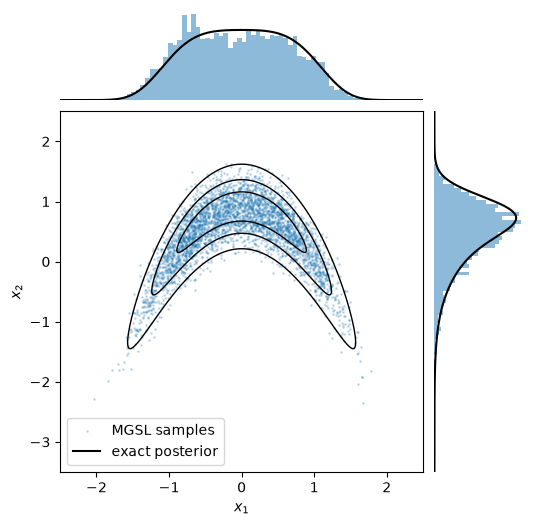

In [5]:
fig = plt.figure(figsize=(6, 6))
grid = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4), wspace=0.05, hspace=0.05)
ax = fig.add_subplot(grid[1, 0])
ax_top = fig.add_subplot(grid[0, 0], sharex=ax)
ax_right = fig.add_subplot(grid[1, 1], sharey=ax)

ax.scatter(samples[:, 0], samples[:, 1], s=1, alpha=0.2, color="C0", label="MGSL samples")
ax.contour(X1, X2, post, levels=post.max() * np.array([0.05, 0.3, 0.7]), colors="k", linewidths=1)
ax.plot([], [], color="k", label="exact posterior")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(loc="lower left")

ax_top.hist(samples[:, 0], bins=60, density=True, color="C0", alpha=0.5)
ax_top.plot(x1, post.sum(0) * dx2, color="k")
ax_right.hist(
    samples[:, 1], bins=60, density=True, color="C0", alpha=0.5, orientation="horizontal"
)
ax_right.plot(post.sum(1) * dx1, x2, color="k")
ax_top.axis("off")
ax_right.axis("off")
plt.show()

## Diagnostics

The local effective sample size (ESS) fraction of each path's local fits, against the
observation time `tau`. It is 1 when the local Gaussian matches the localising distribution;
it dips where the posterior is curved and returns to 1 as the paths localise.

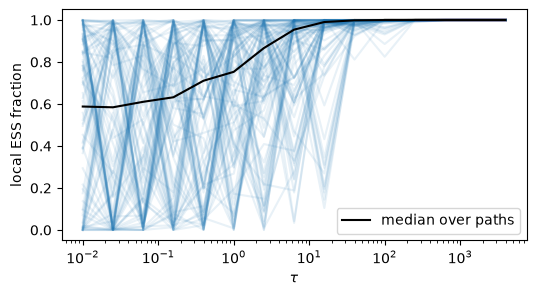

solver failures: {'draw_cg_capped': 0, 'newton_cg_capped': 0, 'cg_breakdowns': 0, 'sd_fallbacks': 0, 'line_search_failures': 0, 'nonfinite': 0}


In [6]:
d = result.diagnostics
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogx(d.taus, d.ess_fraction[:100].T, color="C0", alpha=0.1)
ax.semilogx(d.taus, np.median(d.ess_fraction, 0), color="k", label="median over paths")
ax.set_xlabel(r"$\tau$")
ax.set_ylabel("local ESS fraction")
ax.legend()
plt.show()

print("solver failures:", result.failures.totals())